In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/default-of-credit-card-clients-dataset/UCI_Credit_Card.csv
Using: /kaggle/input/datasets/uciml/default-of-credit-card-clients-dataset/UCI_Credit_Card.csv
Rows, columns: (30000, 25)
Default rate: 0.221
Number of input columns: 20
Logistic regression: AUC = 0.704, Gini = 0.409
LightGBM: AUC = 0.777, Gini = 0.554


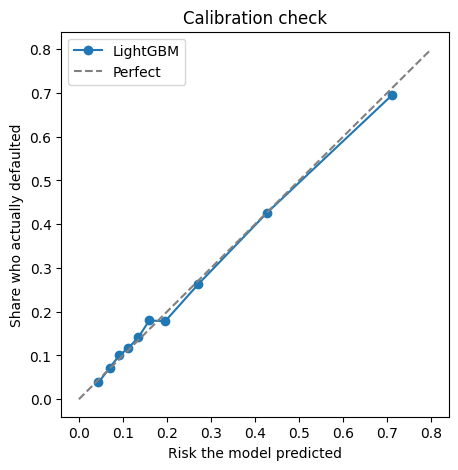

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


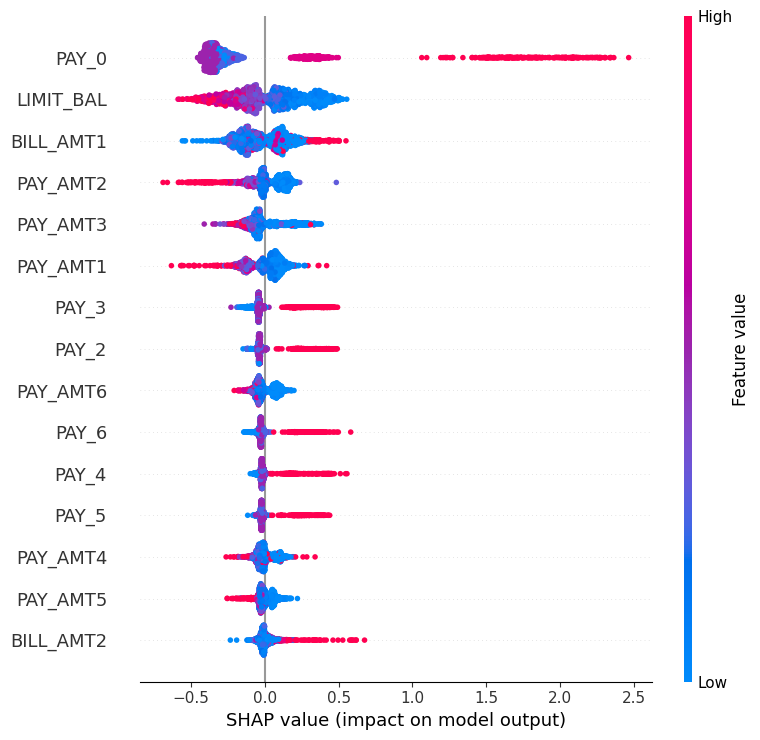

Predicted default risk: 92%
Main reasons: PAY_0 = 3.00; LIMIT_BAL = 10000.00; PAY_6 = 7.00

Predicted default risk: 92%
Main reasons: PAY_0 = 3.00; PAY_6 = 7.00; LIMIT_BAL = 20000.00

Predicted default risk: 89%
Main reasons: PAY_0 = 2.00; PAY_6 = 6.00; LIMIT_BAL = 10000.00



In [ ]:


# %% 1. Find the data file
import glob
import os

for folder, _, names in os.walk("/kaggle/input"):
    for n in names:
        print(os.path.join(folder, n))


# %% 2. Imports and load data (works with the CSV or the Excel version)
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

files = glob.glob("/kaggle/input/**/*.csv", recursive=True) + glob.glob(
    "/kaggle/input/**/*.xls*", recursive=True
)
# Prefer a file with "credit" in its name; otherwise take whatever is there
preferred = [f for f in files if "credit" in os.path.basename(f).lower()]
path = (preferred or files)[0]
print("Using:", path)

if path.endswith(".csv"):
    df = pd.read_csv(path)
else:
    # Excel version from UCI has an extra header row. If this fails, run: !pip install xlrd
    df = pd.read_excel(path, header=1)

df.columns = [str(c).strip() for c in df.columns]

# Give the answer column a simple name, whatever it was called
target_col = [c for c in df.columns if c.lower().startswith("default")][0]
df = df.rename(columns={target_col: "TARGET"})

print("Rows, columns:", df.shape)
print("Default rate:", round(df["TARGET"].mean(), 3))  # about 22% default


# %% 3. Prepare the data
# Gender, age and marital status are NOT used to make decisions
# (UK lenders can't use them). We keep them aside only to check fairness later.
sensitive = df[["SEX", "AGE", "MARRIAGE"]].copy()
sensitive["SEX"] = sensitive["SEX"].map({1: "male", 2: "female"})

drop_cols = ["ID", "TARGET", "SEX", "AGE", "MARRIAGE"]
X = df.drop(columns=drop_cols)
y = df["TARGET"]
print("Number of input columns:", X.shape[1])


# %% 4. Split into train and test sets
X_train, X_test, y_train, y_test, s_train, s_test = train_test_split(
    X, y, sensitive, test_size=0.2, stratify=y, random_state=42
)


# %% 5. Model A: simple logistic regression (the classic bank model)
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logit.fit(X_train, y_train)
p_logit = logit.predict_proba(X_test)[:, 1]


# %% 6. Model B: LightGBM (stronger, but harder to explain)
gbm = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    random_state=42,
    verbose=-1,
)
gbm.fit(X_train, y_train)
p_gbm = gbm.predict_proba(X_test)[:, 1]


# %% 7. Compare the two models
for name, p in [("Logistic regression", p_logit), ("LightGBM", p_gbm)]:
    auc = roc_auc_score(y_test, p)
    print(f"{name}: AUC = {auc:.3f}, Gini = {2 * auc - 1:.3f}")


# %% 8. Is the model honest about its risk numbers? (calibration)
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

actual, predicted = calibration_curve(y_test, p_gbm, n_bins=10, strategy="quantile")

plt.figure(figsize=(5, 5))
plt.plot(predicted, actual, marker="o", label="LightGBM")
plt.plot([0, 0.8], [0, 0.8], "--", color="grey", label="Perfect")
plt.xlabel("Risk the model predicted")
plt.ylabel("Share who actually defaulted")
plt.title("Calibration check")
plt.legend()
plt.show()
# Points close to the dashed line = when the model says 10%, about 10% default.


# %% 9. Explain the model with SHAP
# If this fails with "No module named shap", run in a cell first:  !pip install shap
import shap

explainer = shap.TreeExplainer(gbm)
sample = X_test.sample(2000, random_state=42)
sv = explainer.shap_values(sample)

# Different shap versions return slightly different shapes; make it a 2D array
if isinstance(sv, list):
    sv = sv[1]
if getattr(sv, "ndim", 2) == 3:
    sv = sv[:, :, 1]

shap.summary_plot(sv, sample, max_display=15)
# Top of the chart = the inputs that matter most overall.


# %% 10. Plain-language reasons for individual decisions
risk = gbm.predict_proba(sample)[:, 1]


def top_reasons(i, n=3):
    """Return the n inputs that pushed this person's risk up the most."""
    contrib = pd.Series(sv[i], index=sample.columns)
    top = contrib.sort_values(ascending=False).head(n)
    return [f"{feat} = {sample.iloc[i][feat]:.2f}" for feat in top.index]


riskiest = np.argsort(risk)[::-1][:3]
for i in riskiest:
    print(f"Predicted default risk: {risk[i]:.0%}")
    print("Main reasons:", "; ".join(top_reasons(i)))
    print()

Cut-off risk score: 0.333
Overall approval rate: 80.0%
Default rate among approved: 13.6%
    group  people  approval_rate  good_wrongly_rejected  defaulters_approved  \
0  female    3598          0.814                  0.102                0.501   
1    male    2402          0.779                  0.130                0.481   

     AUC  
0  0.780  
1  0.772  

Approval ratio (lowest group / highest group): 0.96
   group  people  approval_rate  good_wrongly_rejected  defaulters_approved  \
0  21-30    2181          0.782                  0.121                0.436   
1  31-40    2105          0.818                  0.105                0.528   
2  41-50    1243          0.810                  0.107                0.541   
3    51+     471          0.777                  0.124                0.470   

     AUC  
0  0.794  
1  0.774  
2  0.755  
3  0.780  

Approval ratio (lowest group / highest group): 0.95


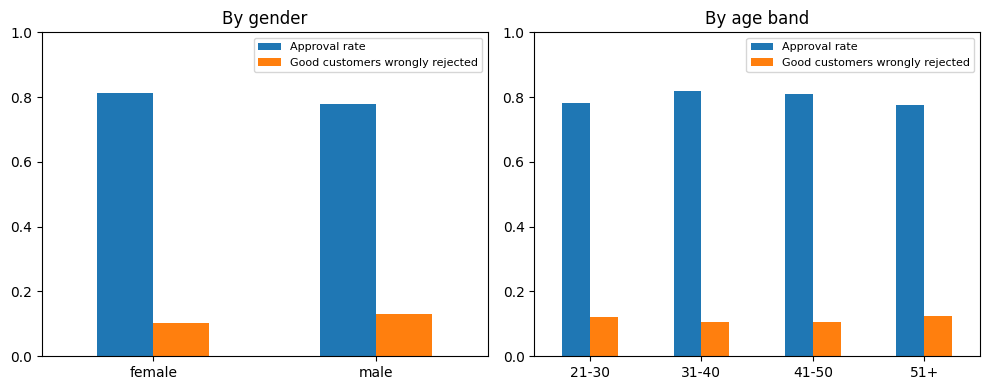

In [2]:
# Credit risk model with fairness checks - Step 3: fairness check
# Run this AFTER credit_risk_full.py, in the same notebook.
# It reuses p_gbm, y_test and s_test from that code.
# Paste each "# %%" block into its own cell.

# %% 1. Set the decision rule: approve the safest 80% of applicants
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

cutoff = np.quantile(p_gbm, 0.80)  # people with risk below this are approved
approved_all = p_gbm < cutoff
print(f"Cut-off risk score: {cutoff:.3f}")
print(f"Overall approval rate: {approved_all.mean():.1%}")
print(f"Default rate among approved: {y_test.values[approved_all].mean():.1%}")


# %% 2. A function that measures how each group is treated
def fairness_table(group, p, y, cutoff):
    rows = []
    for g in sorted(group.dropna().unique(), key=str):
        m = (group == g).values
        approved = p[m] < cutoff
        outcome = y.values[m]
        rows.append(
            {
                "group": g,
                "people": int(m.sum()),
                # share of the group that gets approved
                "approval_rate": approved.mean(),
                # good customers (would repay) who were turned down
                "good_wrongly_rejected": (~approved[outcome == 0]).mean(),
                # customers who later defaulted but were approved
                "defaulters_approved": approved[outcome == 1].mean(),
                # how well the model ranks risk for this group
                "AUC": roc_auc_score(outcome, p[m]),
            }
        )
    return pd.DataFrame(rows).round(3)


# %% 3. Check by gender
sex_table = fairness_table(s_test["SEX"], p_gbm, y_test, cutoff)
print(sex_table)

rates = sex_table.set_index("group")["approval_rate"]
print(f"\nApproval ratio (lowest group / highest group): {rates.min() / rates.max():.2f}")
# A common rule of thumb: a ratio below about 0.80 deserves a closer look.


# %% 4. Check by age band
age_band = pd.cut(
    s_test["AGE"], bins=[20, 30, 40, 50, 100], labels=["21-30", "31-40", "41-50", "51+"]
)
age_table = fairness_table(age_band, p_gbm, y_test, cutoff)
print(age_table)

rates = age_table.set_index("group")["approval_rate"]
print(f"\nApproval ratio (lowest group / highest group): {rates.min() / rates.max():.2f}")


# %% 5. Chart for your README
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, table, title in [
    (axes[0], sex_table, "By gender"),
    (axes[1], age_table, "By age band"),
]:
    table.set_index("group")[["approval_rate", "good_wrongly_rejected"]].plot.bar(
        ax=ax, rot=0
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.legend(["Approval rate", "Good customers wrongly rejected"], fontsize=8)
plt.tight_layout()
plt.show()

                  model  approval_rate  default_rate_among_approved  \
2   Logistic regression            0.6                        0.137   
4   Logistic regression            0.7                        0.136   
6   Logistic regression            0.8                        0.144   
8   Logistic regression            0.9                        0.171   
12             LightGBM            0.6                        0.108   
14             LightGBM            0.7                        0.118   
16             LightGBM            0.8                        0.136   
18             LightGBM            0.9                        0.169   

    defaulters_caught  
2               0.629  
4               0.570  
6               0.478  
8               0.305  
12              0.707  
14              0.626  
16              0.507  
18              0.314  


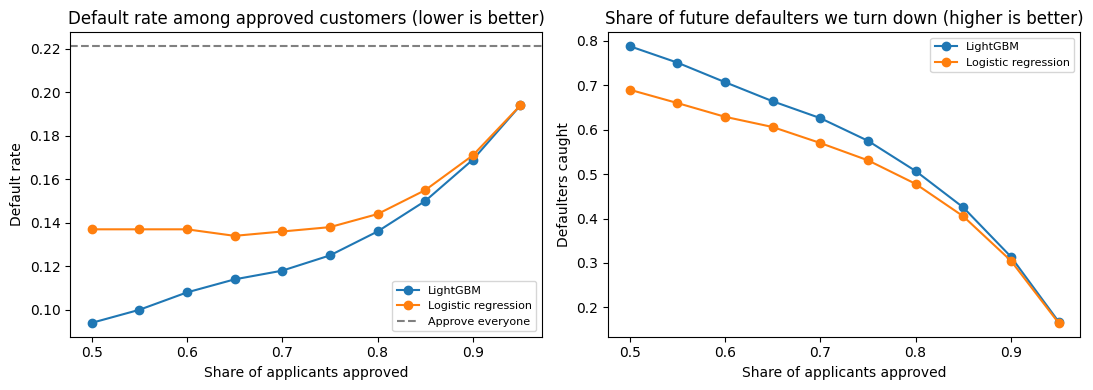

In [3]:
# Credit risk model with fairness checks - Step 4: the business view
# Run this AFTER the fairness code, in the same notebook.
# It reuses p_gbm, p_logit and y_test from the earlier code.
# Paste each "# %%" block into its own cell.

# %% 1. Try different approval levels for both models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

y_arr = y_test.values
rows = []
for model_name, p in [("Logistic regression", p_logit), ("LightGBM", p_gbm)]:
    for approval in np.arange(0.50, 0.96, 0.05):
        cutoff = np.quantile(p, approval)
        approved = p < cutoff
        rows.append(
            {
                "model": model_name,
                "approval_rate": round(approval, 2),
                # of the people we say yes to, how many default?
                "default_rate_among_approved": y_arr[approved].mean(),
                # of the people who would default, how many do we turn down?
                "defaulters_caught": (~approved[y_arr == 1]).mean(),
            }
        )

results = pd.DataFrame(rows).round(3)
print(results[results["approval_rate"].isin([0.60, 0.70, 0.80, 0.90])])


# %% 2. Chart for your README
baseline = y_arr.mean()  # default rate if we approved everyone

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for model_name, grp in results.groupby("model"):
    axes[0].plot(
        grp["approval_rate"], grp["default_rate_among_approved"], marker="o", label=model_name
    )
    axes[1].plot(grp["approval_rate"], grp["defaulters_caught"], marker="o", label=model_name)

axes[0].axhline(baseline, color="grey", linestyle="--", label="Approve everyone")
axes[0].set_title("Default rate among approved customers (lower is better)")
axes[1].set_title("Share of future defaulters we turn down (higher is better)")
for ax in axes:
    ax.set_xlabel("Share of applicants approved")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Default rate")
axes[1].set_ylabel("Defaulters caught")
plt.tight_layout()
plt.show()